# Spectral Clustering
### TMA4205 Numerical Linear Algebra

This project looks at implementation and testing of eigenvalue/eigenvector algorithms, in particular for large, symmetric and sparse matrices. For this we will use spectral clustering, and we thus want to investigate how eigenvectors can be used to improve clustering.

In [24]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.linalg as la
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from scipy.sparse.linalg import eigsh
import time

In [25]:
# Hand-out code

point_size = 10

def make_data(n=100, sigma = 0.5, pl=False):
    '''
    Make four clusters: noisy data points around 4 centres.
    
    Parameters:
    n: number of points in each cluster (default 100)
    sigma: Level of noise (default 0.5)
    pl: Make a plot or not  (default False)

    Return:
    X: the data points, np.array of shape (4*n,2)
    '''
    centers = np.array([[0, 0],[1, 5],[4, 0],[5, 5]])
    X = np.vstack([center + sigma * np.random.randn(n, 2) for center in centers])
    if pl:
        plt.clf()
        plt.scatter(X[:, 0], X[:, 1], s=point_size)
        plt.axis('equal')
        plt.show()
    return X


def make_moons(n = 150, sigma = 0.12, pl = False):
    '''
    Make four half circles.

    Parameters:
    n: Number of data points in each half circle (default 150)
    sigma : Noise level, or the spread of data (default 0.12)
    pl:  Make a plot or not  (default False)

    Return:
    X: The data points, np.array of shape (4*n,2)
    '''
    X = []
    labels = []
    # Four moons, separated spatially
    centers = [(0, 0), (1, 0), (-2.5, -2), (-1, -2)]
    for j, (cx, cy) in enumerate(centers):
        t = np.linspace(0, np.pi, n)
        x = 1.5 * np.cos(t)
        y = 1.5 * np.sin(t)
        # Put the four moons in different orientations
        if j == 1:
            y = -y
        elif j == 2:
            x = -x
        elif j == 3:
            x = -x
            y = -y
        x += cx + sigma*np.random.randn(n)
        y += cy + sigma*np.random.randn(n)
        X.append(np.column_stack((x, y)))
        labels.extend([j]*n)
    X = np.vstack(X)
    labels = np.array(labels)

    if pl:
        plt.clf()
        plt.scatter(X[:,0], X[:,1], c=labels, s=point_size)
        plt.axis("equal")
        plt.show()
    return X


# Part 1: Understanding spectral clustering

In this task we construct a symmetric $k$-nearest-neighbour graph and assign weights to its edges using the Gaussian similarity function
$$
s(x_i, x_j) = \exp \left( \frac{- ||x_i - x_j||_2^2}{2 \sigma^2} \right)
$$
where $\sigma$ controls the width of the neighbourhood.

The unnormalized graph Laplacian matrix is defined as 
$$ L = D - W$$

Below we have implemented an algorithm for spectral clustering, using standard Python functions.

In [26]:
def build_laplacian(X, k=10, sigma=1):
    '''
    Unnormalized graph Laplacian of the symmetric k-nearest-neighbour graph with Gaussian weights.

    Parameters:
        X: The data points, np.array of shape (N,2)
        k: The number of nearest neighbors to use in the graph (default 10)
        sigma: The value of sigma to use in the Gaussian weights (default 1)

    Return:
        L: The Laplacian matrix, scipy sparse matrix of shape (N,N)
    '''

    # Make the k-nearest neighbor graph
    S = kneighbors_graph(X, k, mode='distance', include_self=False)
    S = S.maximum(S.T).tocsr() # Make the graph symmetric

    # Compute the Gaussian weights on the existing edges only (keeps W sparse)
    W = S.copy()
    W.data = np.exp(-W.data**2 / (2 * sigma**2))

    # Compute the degree matrix D and the Laplacian L
    N = W.shape[0]
    D = sp.diags(np.asarray(W.sum(axis=1)).ravel())
    L = (D - W).tocsr()

    return L


def spectral_clustering(X, k=10, K=4, sigma=1):
    '''
    Spectral clustering algorithm.

    Parameters:
        X: The data points, np.array of shape (N,2)
        k: The number of nearest neighbors to use in the graph (default 10)
        K: The number of clusters to find (default 4)
        sigma: The value of sigma to use in the Gaussian weights (default 1)

    Return:
        C: The cluster labels, np.array of shape (N,)
        L: The Laplacian matrix, scipy sparse matrix of shape (N,N)
        lambdas: The eigenvalues of the Laplacian, np.array of shape (N,)
        V: The eigenvectors of the Laplacian, np.array of shape (N,N)
    '''

    # Make the graph Laplacian
    L = build_laplacian(X, k, sigma)

    # Compute the eigenvalues and eigenvectors of the Laplacian
    lambdas, V = la.eigh(L.toarray())
    U = V[:, :K]

    # Perform k-means clustering on the rows of U
    C = KMeans(n_clusters=K, n_init=10, random_state=0).fit(U).labels_

    return C, L, lambdas, V


In [27]:
colors = ["#3FC38B", "#FF8C42", "#4DA3E0", "#F7B731","#F26B6B",
              "#9B6BD6",  "#E85D9E", "#1B5E3F",]

def plot_clusters(X, C, title="Spectral clustering"):
    '''
    Scatter plot of 2D data points coloured by cluster label.

    Parameters:
        X: The data points, np.array of shape (N,2)
        C: The cluster labels, np.array of shape (N,)
        title: The plot title
    '''
    palette = np.array(colors)
    fig, ax = plt.subplots(figsize=(9, 7))

    for c in np.unique(C):
        mask = C == c
        ax.scatter(X[mask, 0], X[mask, 1], s=40, color=palette[c], alpha=0.85,
                   edgecolor="white", linewidth=0.5, label=f"Cluster {c + 1}")

    ax.set_title(title, fontsize=16, pad=12)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal", adjustable="datalim")   # keeps the geometry undistorted
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="best", markerscale=1.2)
    fig.tight_layout()
    plt.show()

Before plotting the clustering results, we are interested in understanding the properties of the Laplacian matrix L. In particular, we want to look at if the following properties are satisfied:

**Proposition 1 (Properties of $L$).** *The matrix $L$ satisfies the following properties:*

1. *For every vector $f \in \mathbb{R}^n$ we have*
$$
f' L f = \frac{1}{2} \sum_{i,j=1}^{n} w_{ij} (f_i - f_j)^2.
$$
2. *$L$ is symmetric and positive semi-definite.*
3. *The smallest eigenvalue of $L$ is $0$, the corresponding eigenvector is the constant one vector $\mathbb{1}$.*
4. *$L$ has $n$ non-negative, real-valued eigenvalues $0 = \lambda_1 \leq \lambda_2 \leq \dots \leq \lambda_n$.*

In [28]:
# Check the properties of the Laplacian matrix for the Gaussian dataset

np.random.seed(0)
X = make_data()
C_gauss, L, lambdas, V = spectral_clustering(X, k=10, K=4, sigma=1)

N = L.shape[0]
W = sp.diags(L.diagonal()) - L          # recover W = D - L (w_ii = 0)
tol0 = 1e-10 * lambdas[-1]               # threshold for "numerically zero"
ones = np.ones(N)

# 1. Quadratic form: f'Lf = 1/2 sum_ij w_ij (f_i - f_j)^2, for a random f
rng = np.random.default_rng(0)
f = rng.standard_normal(N)
lhs = f @ (L @ f)
Wc = W.tocoo()
rhs = 0.5 * np.sum(Wc.data * (f[Wc.row] - f[Wc.col])**2)
print(f"1. f'Lf = {lhs:.6e},  quadratic form = {rhs:.6e},  rel. diff = {abs(lhs - rhs) / abs(lhs):.2e}")

# 2. Symmetric and positive semi-definite
print(f"2. max|L - L^T| = {abs(L - L.T).max():.2e}")
print(f"   lambda_min = {lambdas[0]:.2e}  (PSD up to rounding if >= -tol0 = {-tol0:.1e})")

# 3. Smallest eigenvalue 0 with eigenvector 1
print(f"3. max|L 1| = {np.abs(L @ ones).max():.2e},  lambda_1 = {lambdas[0]:.2e}")

# 4. Real, non-negative eigenvalues (eigvals = general solver, does not assume symmetry)
ev = la.eigvals(L.toarray())
print(f"4. max|Im(lambda)| = {np.abs(ev.imag).max():.2e}")
print(f"   eigenvalues < -tol0 = {np.sum(lambdas < -tol0)}")
print(f"   lambda_1..lambda_6 = {lambdas[:6]}")

# Proposition 2: multiplicity of 0 = number of connected components
m = np.sum(np.abs(lambdas) < tol0)
n_comp, comp_labels = connected_components(W, directed=False)
print(f"Prop. 2: #zero eigenvalues = {m},  #connected components = {n_comp}")


1. f'Lf = 4.745441e+03,  quadratic form = 4.745441e+03,  rel. diff = 0.00e+00
2. max|L - L^T| = 0.00e+00
   lambda_min = 0.00e+00  (PSD up to rounding if >= -tol0 = -1.9e-09)
3. max|L 1| = 5.33e-15,  lambda_1 = 0.00e+00
4. max|Im(lambda)| = 0.00e+00
   eigenvalues < -tol0 = 0
   lambda_1..lambda_6 = [0.00000000e+00 3.55271368e-15 3.55271368e-15 7.10542736e-15
 6.19366152e-01 6.70144618e-01]
Prop. 2: #zero eigenvalues = 4,  #connected components = 4


For **make_data()** ($N = 4n = 400$, $k = 10$, $\sigma = 1$), all four properties hold up to rounding errors, with values below $\text{tol} = 10^{-10}\lambda_{\max} \approx 1.9\cdot 10^{-9}$ treated as zero:

1. $f^TLf$ and $\frac{1}{2}\sum_{i,j} w_{ij} (f_i - f_j)^2$ agree to machine precision for a random $f$.
2. $L$ is exactly symmetric, and $\lambda_{\min} \geq -\text{tol}$. Small negative eigenvalues of order $\varepsilon_{\text{mach}}\lVert L\rVert_2 \approx 4\cdot 10^{-15}$ are rounding errors of a backward stable eigensolver, not a violation of positive semidefiniteness.
3. $\lVert L\mathbb{1}\rVert_\infty \approx 5\cdot 10^{-15}$, so $\mathbb{1}$ lies in the null space.
4. `scipy.linalg.eigvals`, which does not assume symmetry, returns no imaginary parts.

**Proposition 2 (Number of connected components and the spectrum of $L$).** *Let $G$ be an undirected graph with non-negative weights. Then the multiplicity $m$ of the eigenvalue $0$ of $L$ equals the number of connected components $A_1, \dots, A_m$ in the graph. The eigenspace of eigenvalue $0$ is spanned by the indicator vectors $\mathbb{1}_{A_1}, \dots, \mathbb{1}_{A_m}$ of those components.*

The six smallest eigenvalues are $\lambda_1, \dots, \lambda_6 \approx 0,\ 3.6\cdot 10^{-15},\ 3.6\cdot 10^{-15},\ 7.1\cdot 10^{-15},\ 0.62,\ 0.67$. Four eigenvalues are numerically zero, and `connected_components` confirms four components, one per cluster. This is the ideal case: $u_1, \dots, u_4$ span the cluster indicators, so $K$-means on the rows of $U$ trivially recovers the clusters (von Luxburg §7).


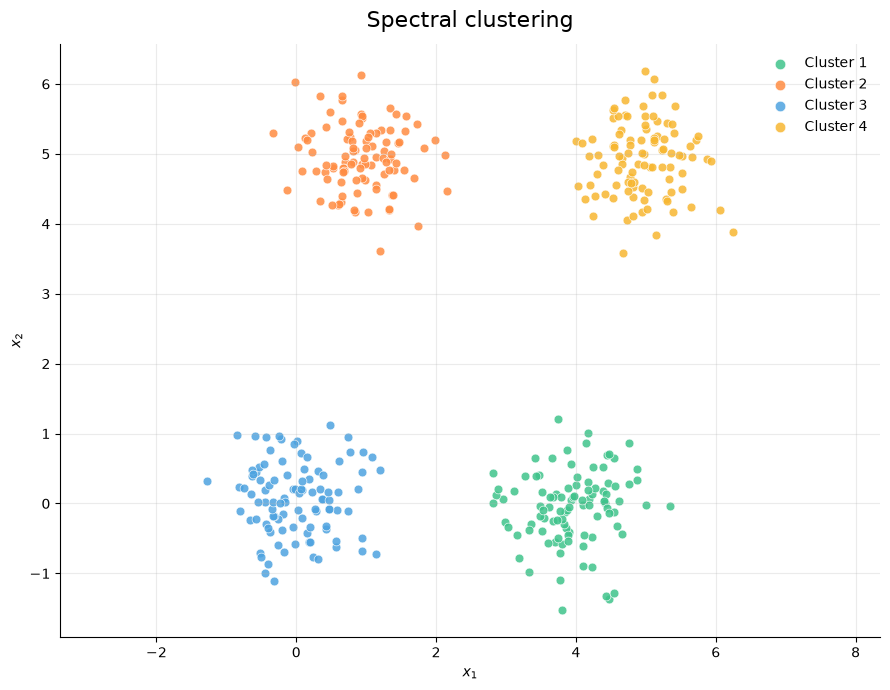

In [29]:
plot_clusters(X, C_gauss, title="Spectral clustering")

The plot shows that all four clusters are recovered correctly.

In [30]:
# Check the properties of the Laplacian matrix for the moons dataset

np.random.seed(0)
Y = make_moons()  
C_moons, L_moons, lambdas_moons, V_moons = spectral_clustering(Y, k=10, K=4, sigma=1)

N = L_moons.shape[0]
W = sp.diags(L_moons.diagonal()) - L_moons          # recover W = D - L (w_ii = 0)
tol0 = 1e-10 * lambdas_moons[-1]               # threshold for "numerically zero"
ones = np.ones(N)

# 1. Quadratic form: f'Lf = 1/2 sum_ij w_ij (f_i - f_j)^2, for a random f
rng = np.random.default_rng(0)
f = rng.standard_normal(N)
lhs = f @ (L_moons @ f)
Wc = W.tocoo()
rhs = 0.5 * np.sum(Wc.data * (f[Wc.row] - f[Wc.col])**2)
print(f"1. f'Lf = {lhs:.6e},  quadratic form = {rhs:.6e},  rel. diff = {abs(lhs - rhs) / abs(lhs):.2e}")

# 2. Symmetric and positive semi-definite
print(f"2. max|L - L^T| = {abs(L_moons - L_moons.T).max():.2e}")
print(f"   lambda_min = {lambdas_moons[0]:.2e}  (PSD up to rounding if >= -tol0 = {-tol0:.1e})")

# 3. Smallest eigenvalue 0 with eigenvector 1
print(f"3. max|L 1| = {np.abs(L_moons @ ones).max():.2e},  lambda_1 = {lambdas_moons[0]:.2e}")

# 4. Real, non-negative eigenvalues (eigvals = general solver, does not assume symmetry)
ev = la.eigvals(L_moons.toarray())
print(f"4. max|Im(lambda)| = {np.abs(ev.imag).max():.2e}")
print(f"   eigenvalues < -tol0 = {np.sum(lambdas_moons < -tol0)}")
print(f"   lambda_1..lambda_6 = {lambdas_moons[:6]}")

# Proposition 2: multiplicity of 0 = number of connected components
m = np.sum(np.abs(lambdas_moons) < tol0)
n_comp, comp_labels = connected_components(W, directed=False)
print(f"Prop. 2: #zero eigenvalues = {m},  #connected components = {n_comp}")

1. f'Lf = 7.068196e+03,  quadratic form = 7.068196e+03,  rel. diff = 1.29e-16
2. max|L - L^T| = 0.00e+00
   lambda_min = -7.54e-15  (PSD up to rounding if >= -tol0 = -1.9e-09)
3. max|L 1| = 5.33e-15,  lambda_1 = -7.54e-15
4. max|Im(lambda)| = 0.00e+00
   eigenvalues < -tol0 = 0
   lambda_1..lambda_6 = [-7.54438635e-15 -3.55271368e-15  2.08767222e-15  1.29565798e-02
  3.45712613e-02  3.51343227e-02]
Prop. 2: #zero eigenvalues = 3,  #connected components = 3


For **make_moons()** ($N = 4n = 600$, $k = 10$, $\sigma = 1$), all four properties again hold up to rounding errors, with the same threshold. In particular, $\lambda_{\min} \approx -7.5\cdot 10^{-15}$ is of the order of the rounding error $\varepsilon_{\text{mach}}\lVert L\rVert_2$.

The six smallest eigenvalues are $\lambda_1, \dots, \lambda_6 \approx -7.5\cdot 10^{-15},\ -3.6\cdot 10^{-15},\ 2.1\cdot 10^{-15},\ 1.3\cdot 10^{-2},\ 3.46\cdot 10^{-2},\ 3.51\cdot 10^{-2}$. Only three eigenvalues are numerically zero, and `connected_components` confirms three components: the right and bottom moons are joined by a few edges. This is the "nearly ideal" case (von Luxburg §7), where the merged component is split by $u_4$ with small but nonzero $\lambda_4 \approx 1.3\cdot 10^{-2}$. The eigengap $\lambda_5 - \lambda_4 \approx 2.2\cdot 10^{-2}$ is much smaller than for the Gaussian clusters ($\approx 0.62$).

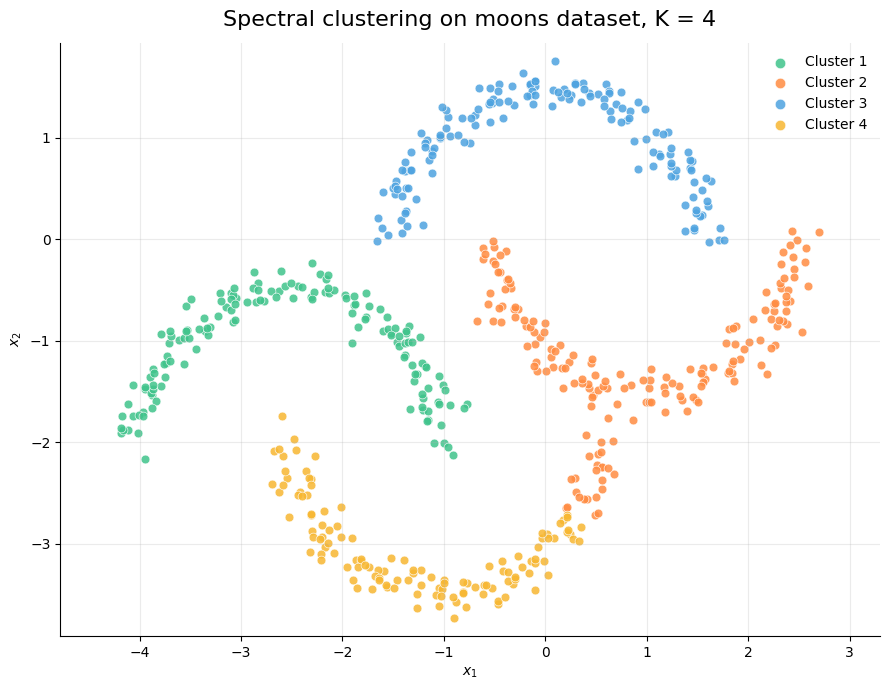

In [31]:
plot_clusters(Y, C_moons, title="Spectral clustering on moons dataset, K = 4")

With $\sigma = 1$ and $K = 4$, the top and left moons are recovered exactly. The right moon and the bottom moon form one connected component, and the cut through it is misplaced: the right end of the bottom moon is assigned to the right moon.

sigma = 0.237


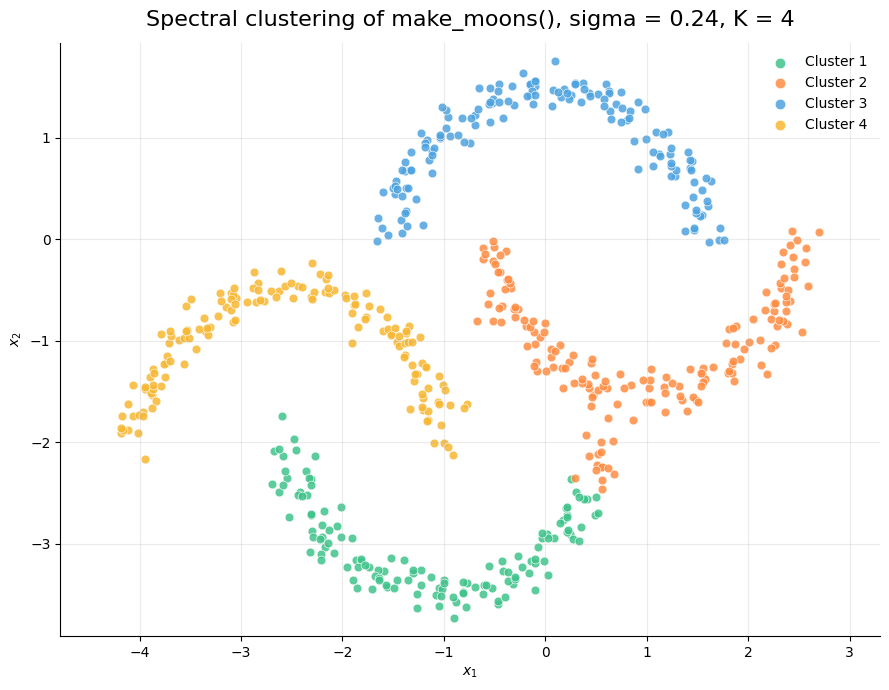

In [32]:
# Rule of thumb (von Luxburg §8.1): sigma = mean distance to the k-th nearest neighbour
sigma_moons = kneighbors_graph(Y, 10, mode='distance').max(axis=1).toarray().mean()
print(f"sigma = {sigma_moons:.3f}")

C_moons_s, L_moons_s, lambdas_moons_s, V_moons_s = spectral_clustering(Y, k=10, K=4, sigma=sigma_moons)
plot_clusters(Y, C_moons_s, f"Spectral clustering of make_moons(), sigma = {sigma_moons:.2f}, K = 4")

With $\sigma = \bar d_k = 0.237$, the result is essentially unchanged (cluster colours are permuted, since the labelling is arbitrary). In a $k$-NN graph, $\sigma$ only reweights existing edges and cannot remove the edges between the two touching moons, so the misplaced cut remains.

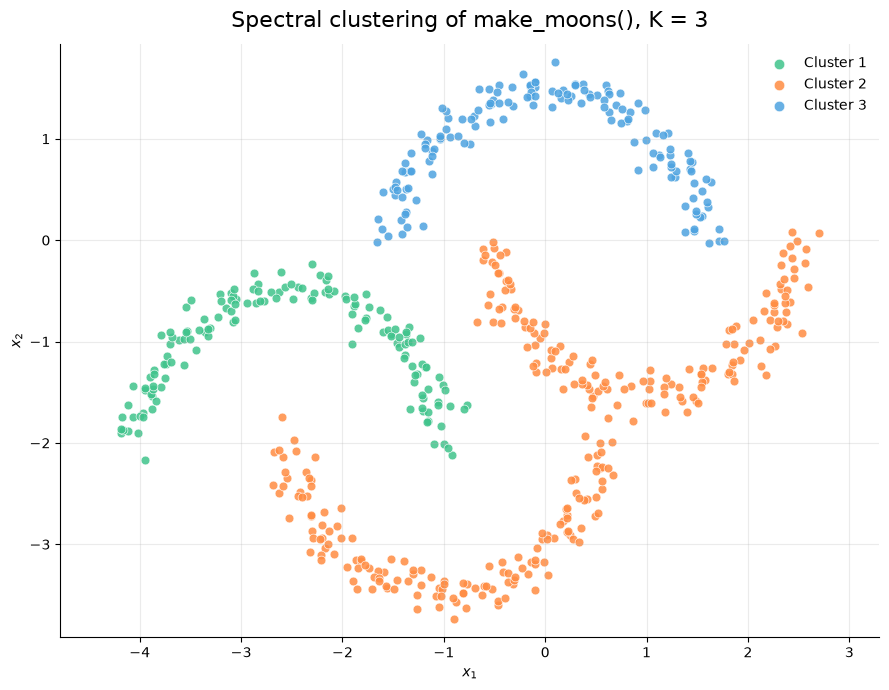

In [33]:
C_moons_3, _, _, _ = spectral_clustering(Y, k=10, K=3, sigma=1)
plot_clusters(Y, C_moons_3, f"Spectral clustering of make_moons(), K = 3")

With $K = 3$, equal to the number of connected components, spectral clustering returns exactly the components: the right and bottom moons are merged into one cluster (von Luxburg §8.1).

**Choice of $\sigma$.** Following von Luxburg (§8.1), we compare $\sigma=1$ to $\sigma$ on the order of the mean distance to the $k$-th nearest neighbour, $\sigma = \bar d_k \approx 0.24$ for the moons ($k = 10$). Both choices give practically the same clustering, since $\sigma$ does not change the connectivity of the $k$-NN graph. The clustering here is determined by the graph connectivity, thus we keep  $\sigma = 1$ as the main choice.

**Choice of $K$.** The data consists of four moons by construction, so $K = 4$. The eigengap heuristic (von Luxburg §8.3) is ambiguous here: $\lambda_1, \lambda_2, \lambda_3 \approx 0$ followed by $\lambda_4 \approx 1.3\cdot 10^{-2}$ suggests $K = 3$, while the gap $\lambda_5 - \lambda_4 \approx 2.2\cdot 10^{-2}$ supports $K = 4$. For the Gaussian clusters, the heuristic clearly gives $K = 4$ ($\lambda_1, \dots, \lambda_4 \approx 0$, $\lambda_5 \approx 0.62$).

In [34]:
for k in [4, 5, 6, 7, 8, 10]:
    S = kneighbors_graph(Y, k, mode='distance', include_self=False)
    print(f"k = {k:2d}: components = {connected_components(S.maximum(S.T), directed=False)[0]}")

k =  4: components = 7
k =  5: components = 3
k =  6: components = 3
k =  7: components = 3
k =  8: components = 3
k = 10: components = 3


For $k \geq 5$ the graph always has three components, while $k = 4$ already breaks the moons into seven pieces. No choice of $k$ separates the right and bottom moons without fragmenting the others, so with the unnormalized Laplacian and a symmetric $k$-NN graph these two moons cannot be fully separated on this sample.

***Add plain K-means vs spectral clustering plot??***

# Part 2: Implement and test eigenvalue/eigenvector solvers

In this part we will implement and investigate three different eigenvalue algorithms:
* Power iteration
* QR iteration
* Lanczos iteration

## Power Iteration
Power iteration in itself can only find the eigenvector corresponding to the largest eigenvalue. In our project, we are interested in the smallest eigenvalues, and therefore need to adapt the algorithm accordingly. We will use shift and flip, thus applying power iteration to 
$$B = cI - L, \quad \lambda_i(B) = c - \lambda_i(L)$$
with $c \geq 2d_{max}$.

B has the same eigenvectors as L, but the order is reversed. The smallest eigenvalue of L becomes the dominant one of B, and we can recover it as $\lambda(L) = c - \lambda(B)$.

In [35]:
def power_iteration(L, tol=1e-10, maxiter=1000, seed=0, c=None, found=None, callback=None):
    """
    Power iteration algorithm to compute the dominant eigenvalue and eigenvector of the graph Laplacian L.

    Parameters:
        L: The input matrix (sparse or dense)
        tol: The tolerance for convergence
        maxiter: The maximum number of iterations
        seed: The seed for the random number generator
        c: The shift. If None, power iteration is applied to L. If given, it is applied to c*I - L (requires c >= lambda_max(L)), which gives the smallest eigenpair of L.
        found: Optional list of previously computed eigenvectors (orthonormal). If given, the iterates are kept
               orthogonal to these vectors (deflation), so the method converges to the next eigenpair.
        callback: Optional function callback(lambda, v), called in every iteration with the current eigenvalue
                  estimate of L (shifted back if c is given) and the iterate v^(k). Used for the error plots.

    Returns:
        lambda^(k): The dominant eigenvalue after k iterations
        v^(k): The dominant eigenvector after k iterations
        k: The number of iterations performed
        converged: A boolean indicating whether the algorithm converged within the specified tolerance
        history: A list of residuals at each iteration
    """

    def apply(x):
        # Matrix-vector multiplication with L, or with the shifted matrix c*I - L
        return L @ x if c is None else c * x - L @ x

    # Deflation: matrix X with the found eigenvectors as columns
    X = np.column_stack(found) if found else None

    def deflate(x):
        # Deflation: remove the components of x along the found eigenvectors, x - X X^T x
        return x if X is None else x - X @ (X.T @ x)

    # Initialize a random vector v^(0), orthogonal to the found eigenvectors
    rng = np.random.default_rng(seed)
    v = deflate(rng.standard_normal(L.shape[0]))
    v = v / la.norm(v) # Normalize the vector

    w = deflate(apply(v))   # Initial matrix-vector multiplication: w = A v^(0), deflated
    converged = False  # Flag to check for convergence
    history = []

    for k in range(1, maxiter+1):
        v = w / la.norm(w)  # Normalize the vector, v^(k) = A v^(k-1) / ||A v^(k-1)||

        # Deflation in every iteration: rounding errors would otherwise reintroduce the found directions
        w = deflate(apply(v))  # Matrix-vector multiplication, A v^(k), reused in the next iteration

        lambda_ = v @ w  # Rayleigh quotient to estimate the eigenvalue, lambda^(k) = (v^(k))^T A v^(k)
        res = la.norm(w - lambda_ * v)  # Compute the residual of the pair (lambda^(k), v^(k))
        history.append(res)  # Store the residual for analysis
        if callback is not None:
            callback(lambda_ if c is None else c - lambda_, v)
        if res < tol: # Check for convergence
            converged = True
            break

    if c is not None:
        lambda_ = c - lambda_  # Shift back: eigenvalue of L = c - eigenvalue of c*I - L

    return lambda_, v, k, converged, history


In [36]:
# Simple check of power_iteration on a small matrix with known eigenpairs
A = np.diag([1.0, 2.0, 5.0])    # eigenvalues 1, 2, 5; eigenvectors e_1, e_2, e_3

# Largest eigenpair: expect lambda = 5 and v = (0, 0, ±1)
lam, v, n_iter, conv, hist = power_iteration(A)
print("Largest: ", lam, v, n_iter, conv)

# Smallest eigenpair with shift c = 6 >= 5: expect lambda = 1 and v = (±1, 0, 0)
lam, v, n_iter, conv, hist = power_iteration(A, c=6)
print("Smallest:", lam, v, n_iter, conv)

Largest:  5.0 [ 6.58753427e-19 -2.32247959e-11  1.00000000e+00] 25 True
Smallest: 1.0 [ 1.00000000e+00 -8.76673288e-11  1.03310997e-72] 104 True


In [37]:
# Smallest eigenpair of L with shifted power iteration
d = L.diagonal()    # degrees d_i (diagonal of L)
c = 2 * d.max() # Gershgorin: lambda_max(L) <= 2 max_i d_i, so c >= lambda_max

lam, v, n_iter, conv, hist = power_iteration(L, maxiter=10000, c=c)

# Reference solution: lambdas, V from spectral_clustering above
tol0 = 1e-10 * lambdas[-1]  # threshold for "numerically equal"
m = np.sum(lambdas - lambdas[0] < tol0) # multiplicity of lambda_1
Q = V[:, :m]    # orthonormal basis of the eigenspace of lambda_1

print(f"c = {c:.3f},  converged = {conv},  iterations = {n_iter}")
print(f"Eigenvalue: {lam}")
print(f"Eigenvalue error |lam - lambda_1| = {abs(lam - lambdas[0]):.2e}")
print(f"Multiplicity of lambda_1: m = {m}")
print(f"Distance from v to span(u_1..u_m) = {la.norm(v - Q @ (Q.T @ v)):.2e}")
print(f"Overlap |v^T u_1| = {abs(v @ V[:, 0]):.2f}")

c = 34.861,  converged = True,  iterations = 1231
Eigenvalue: 7.105427357601002e-15
Eigenvalue error |lam - lambda_1| = 7.11e-15
Multiplicity of lambda_1: m = 4
Distance from v to span(u_1..u_m) = 1.60e-10
Overlap |v^T u_1| = 0.29


Converged in 1231 iterations ($c = 2d_{\max} \approx 34.9$, tol $= 10^{-10}$). Since $\lambda_1 = 0$ has multiplicity $m = 4$, $v$ converges to some vector in $\operatorname{span}(u_1, \dots, u_4)$, not to $u_1$ itself, hence the overlap $0.29$. The distance $1.6 \cdot 10^{-10}$ to this eigenspace matches the bound $\|Lv - \lambda v\|/(\lambda_5 - \lambda_1) \approx 10^{-10}/0.62$. Power iteration found a correct eigenvector for $\lambda = 0$, but since there are four of them, it found an arbitrary mix of them. That’s why, for clustering, we need a method that finds all four at once, such as deflation.

In [38]:
# K smallest eigenpairs of L with shifted power iteration and deflation
n_pairs = 6
found = []
lams = []
for j in range(n_pairs):
    lam, v, n_iter, conv, hist = power_iteration(L, maxiter=100000, c=c, found=found)
    found.append(v)
    lams.append(lam)
    print(f"Eigenpair {j+1}: lambda = {lam:.2e}, iterations = {n_iter}, converged = {conv}")

U = np.column_stack(found)   # N x n_pairs matrix with the computed eigenvectors as columns

Eigenpair 1: lambda = 7.11e-15, iterations = 1231, converged = True
Eigenpair 2: lambda = 7.11e-15, iterations = 3158, converged = True
Eigenpair 3: lambda = 2.13e-14, iterations = 3291, converged = True
Eigenpair 4: lambda = -2.13e-14, iterations = 3257, converged = True
Eigenpair 5: lambda = 6.19e-01, iterations = 13705, converged = True
Eigenpair 6: lambda = 6.70e-01, iterations = 25181, converged = True


Gaussian clusters: c = 34.861
  run 1: lambda = 7.105e-15, iterations = 1231, converged = True, r theory = 0.982233, r observed = 0.981904
  run 2: lambda = -1.421e-14, iterations = 1252, converged = True, r theory = 0.982233, r observed = 0.982121
  run 3: lambda = -7.105e-15, iterations = 1330, converged = True, r theory = 0.982233, r observed = 0.982213
  run 4: lambda = 0.000e+00, iterations = 1259, converged = True, r theory = 0.982233, r observed = 0.982124
  run 5: lambda = 6.194e-01, iterations = 13608, converged = True, r theory = 0.998517, r observed = 0.998517
  run 6: lambda = 6.701e-01, iterations = 29159, converged = True, r theory = 0.999277, r observed = 0.999277
Moons: c = 35.404
  run 1: lambda = 7.105e-15, iterations = 48472, converged = True, r theory = 0.999634, r observed = 0.999634
  run 2: lambda = -5.684e-14, iterations = 52010, converged = True, r theory = 0.999634, r observed = 0.999634
  run 3: lambda = 7.105e-15, iterations = 47553, converged = True, r theo

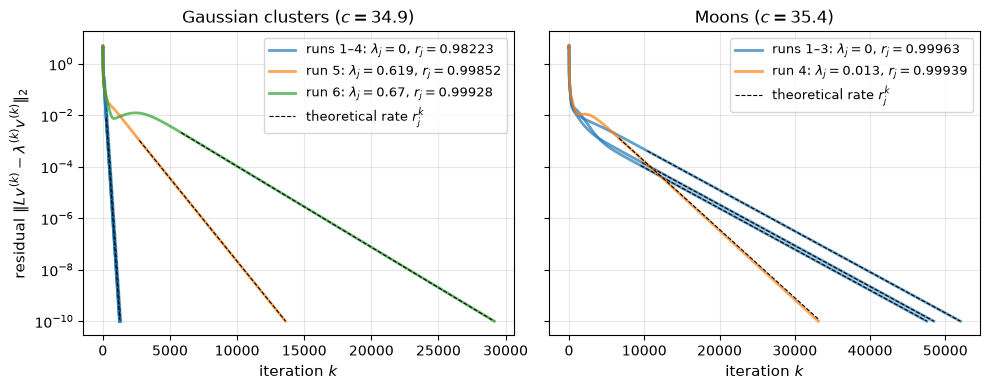

In [39]:
def theoretical_rate(lambdas, j, c, tol0):
    '''
    Theoretical convergence rate of shifted power iteration with deflation for eigenpair j,
    r_j = (c - lambda_next) / (c - lambda_j), where lambda_next is the next distinct eigenvalue.

    Parameters:
        lambdas: Eigenvalues of L in ascending order, np.array of shape (N,)
        j: Index of the eigenpair
        c: The shift
        tol0: Threshold for "numerically equal" eigenvalues

    Return:
        r: The theoretical rate
    '''
    i_next = np.argmax(lambdas > lambdas[j] + tol0)
    return (c - lambdas[i_next]) / (c - lambdas[j])


def deflation_convergence(L, lambdas, n_pairs, name, ax, tol=1e-10, maxiter=50000):
    '''
    Compute the n_pairs smallest eigenpairs of L with shifted power iteration and deflation, and plot the
    residual history of each run against the theoretical rate r_j = (c - lambda_next) / (c - lambda_j).

    Parameters:
        L: The graph Laplacian, scipy sparse matrix of shape (N,N)
        lambdas: Reference eigenvalues of L in ascending order, np.array of shape (N,)
        n_pairs: The number of eigenpairs to compute
        name: Name of the data set, used in the title and printout
        ax: Matplotlib axes to plot in
        tol: Tolerance for power iteration
        maxiter: The maximum number of iterations per run

    Return:
        U: The computed eigenvectors as columns, np.array of shape (N,n_pairs)
        lams: The computed eigenvalues, np.array of shape (n_pairs,)
    '''

    c = 2 * L.diagonal().max()
    tol0 = 1e-10 * lambdas[-1]

    found = []
    lams = []
    runs = []
    print(f"{name}: c = {c:.3f}")
    for j in range(n_pairs):
        lam, v, n_iter, conv, hist = power_iteration(L, tol=tol, maxiter=maxiter, seed=j, c=c, found=found)
        found.append(v)
        lams.append(lam)

        # Theoretical rate: gap from lambda_{j+1} to the next distinct eigenvalue
        r = theoretical_rate(lambdas, j, c, tol0)

        # Observed rate from a log-linear fit, skipping the initial transient
        hist = np.array(hist)
        ks = np.arange(1, len(hist) + 1)
        k0 = len(hist) // 5
        r_obs = np.exp(np.polyfit(ks[k0:], np.log(hist[k0:]), 1)[0])

        runs.append(dict(j=j, r=r, hist=hist, ks=ks, k0=k0))
        print(f"  run {j+1}: lambda = {lam:.3e}, iterations = {n_iter}, converged = {conv}, "
              f"r theory = {r:.6f}, r observed = {r_obs:.6f}")

    # Plot: one colour per distinct eigenvalue (runs with the same eigenvalue share colour and legend entry)
    groups = []
    for j in range(n_pairs):
        if j > 0 and abs(lambdas[j] - lambdas[j - 1]) < tol0:
            groups[-1].append(j)
        else:
            groups.append([j])

    colours = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for colour, group in zip(colours, groups):
        j0, j1 = group[0], group[-1]
        runs_label = f"run {j0 + 1}" if j0 == j1 else f"runs {j0 + 1}–{j1 + 1}"
        lam_label = "0" if abs(lambdas[j0]) < tol0 else f"{lambdas[j0]:.3g}"
        for j in group:
            run = runs[j]
            ks, k0 = run["ks"], run["k0"]
            ax.semilogy(ks, run["hist"], color=colour, lw=2, alpha=0.7,
                        label=f"{runs_label}: $\\lambda_j = {lam_label}$, $r_j = {run['r']:.5f}$" if j == j0 else None)
            # Theory line after the transient
            ax.semilogy(ks[k0:], run["hist"][k0 - 1] * run["r"]**(ks[k0:] - k0), "k--", lw=0.8)

    ax.plot([], [], "k--", lw=0.8, label="theoretical rate $r_j^k$")   # one legend entry for all theory lines
    ax.set_xlabel("iteration $k$", fontsize=11)
    ax.set_title(f"{name} ($c = {c:.1f}$)", fontsize=12)
    ax.tick_params(labelsize=10)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9.5)
    return np.column_stack(found), np.array(lams)


fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
U_gauss, lams_gauss = deflation_convergence(L, lambdas, n_pairs=6, name="Gaussian clusters", ax=axes[0])
U_moons, lams_moons = deflation_convergence(L_moons, lambdas_moons, n_pairs=4, name="Moons", ax=axes[1], maxiter=100000)
axes[0].set_ylabel(r"residual $\|Lv^{(k)} - \lambda^{(k)} v^{(k)}\|_2$", fontsize=11)
fig.tight_layout()
plt.show()

**Gaussian clusters.** All six eigenpairs converge, and the measured rates match the theoretical ones almost exactly (dashed lines). Runs 1–4 all belong to the eigenvalue $0$ and converge equally fast, in about 1250 iterations. Runs 5 and 6 are much slower (about 14 000 and 29 000 iterations), because their eigenvalues are close to the next ones ($0.62$, $0.67$, ...). The bump at the start of run 6 is not an error: the residual first grows while the vector turns from $u_7$ towards $u_6$, and then decreases as expected.

**Moons.** Again the measured rates match theory. Runs 1–3 (eigenvalue $0$) need 47 500–52 000 iterations each, roughly 40 times more than for the Gaussian clusters, because the next eigenvalue $\lambda_4 \approx 0.013$ is very close to $0$. Run 4 converges a bit faster, since the gap from $\lambda_4$ to $\lambda_5 \approx 0.035$ is larger. Smaller gaps between eigenvalues make power iteration slower.

#### Dependence on size and sparsity
Shifted power iteration with deflation for the 4 smallest eigenpairs of `make_data` Laplacians, $c = 2d_{\max}$, tol $= 10^{-10}$, maxiter $= 50\,000$ per eigenpair, seed $j$ for run $j$, $\sigma = 1$. Size: $k = 10$, $N = 200, \dots, 6400$. Sparsity: $N = 400$, $k = 5, \dots, 160$. Reference: `scipy.sparse.linalg.eigsh` (shift-invert).

Size (k = 10, sigma = 1, tol = 1e-10, maxiter = 50000 per eigenpair):
       N       nnz   nnz_row         c         m      lam5       its      pred      conv    t_iter   t_power   t_eigsh
     200      2778      13.9      35.8         4       1.1      2851  3.12e+03      True  1.11e-05    0.0436   0.00853
     400      5446      13.6      34.9         4     0.619      5072  5.47e+03      True  1.39e-05    0.0705   0.00266
     800     10656      13.3      35.7         4     0.345      9123  1.01e+04      True  2.02e-05     0.166   0.00513
    1600     20884      13.1      37.5         4      0.15     21314  2.43e+04      True  3.96e-05     0.778    0.0124
    3200     41224      12.9      35.9         2    0.0825    159431  3.26e+06     False  7.02e-05      9.72    0.0289
    6400     81266      12.7      37.9         3     0.044    167358  1.99e+06     False  0.000123      17.7    0.0585

Sparsity (N = 400, sigma = 1, tol = 1e-10, maxiter = 50000 per eigenpair):
       k         N   

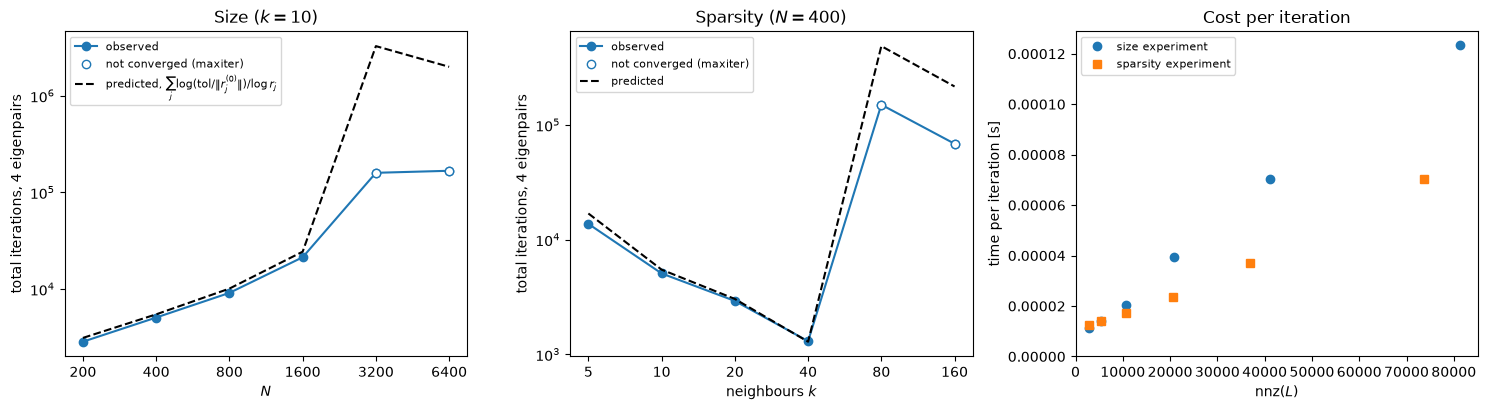

In [40]:
def power_experiment(L, n_pairs=4, tol=1e-10, maxiter=50000):
    '''
    Compute the n_pairs smallest eigenpairs of L with shifted power iteration and deflation (own implementation),
    and compare with the iteration count predicted by r_j^k and with scipy.sparse.linalg.eigsh (library).

    Parameters:
        L: The graph Laplacian, scipy sparse matrix of shape (N,N)
        n_pairs: The number of eigenpairs to compute (default 4)
        tol: Tolerance for power iteration
        maxiter: The maximum number of iterations per run

    Return:
        dict with size, sparsity, spectrum, iteration counts and timings
    '''
    N = L.shape[0]
    c = 2 * L.diagonal().max()

    # Reference (library): shift-invert eigsh around -1e-3, so that L + 1e-3 I is SPD
    t0 = time.perf_counter()
    ref = np.sort(eigsh(L, k=n_pairs + 6, sigma=-1e-3, which='LM', return_eigenvectors=False))
    t_eigsh = time.perf_counter() - t0
    tol0 = 1e-8 * c                                # threshold for "numerically equal"

    # Own implementation: n_pairs deflated runs, with the predicted iteration count for each run
    found, its, preds, convs = [], [], [], []
    t0 = time.perf_counter()
    for j in range(n_pairs):
        lam, v, n_iter, conv, hist = power_iteration(L, tol=tol, maxiter=maxiter, seed=j, c=c, found=found)
        found.append(v); its.append(n_iter); convs.append(conv)
        r_j = theoretical_rate(ref, j, c, tol0)
        preds.append(np.log(tol / hist[0]) / np.log(r_j))        # k such that ||res_0|| r_j^k = tol
    t_power = time.perf_counter() - t0

    # Cost per iteration: a fixed number of iterations (tol = 0, so no early stop), best of 5 repeats
    n_time = 500
    t_runs = []
    for _ in range(5):
        t0 = time.perf_counter()
        power_iteration(L, tol=0, maxiter=n_time, c=c, found=found[:-1])
        t_runs.append(time.perf_counter() - t0)
    t_iter = min(t_runs) / n_time

    return dict(N=N, nnz=L.nnz, nnz_row=L.nnz / N, c=c,
                m=int(np.sum(ref < tol0)),                       # multiplicity of 0 = connected components
                lam5=ref[n_pairs], its=sum(its), pred=sum(preds), conv=all(convs),
                t_iter=t_iter, t_power=t_power, t_eigsh=t_eigsh)


def print_table(rows, keys):
    print("  ".join(f"{key:>8}" for key in keys))
    for row in rows:
        print("  ".join(f"{row[key]:>8.3g}" if isinstance(row[key], float) else f"{row[key]!s:>8}" for key in keys))


keys = ["N", "nnz", "nnz_row", "c", "m", "lam5", "its", "pred", "conv", "t_iter", "t_power", "t_eigsh"]

# Experiment 1: size. Fixed k = 10, sigma = 1, N = 4n grows
size_rows = []
for n in [50, 100, 200, 400, 800, 1600]:
    np.random.seed(0)
    size_rows.append(power_experiment(build_laplacian(make_data(n=n), k=10)))
print("Size (k = 10, sigma = 1, tol = 1e-10, maxiter = 50000 per eigenpair):")
print_table(size_rows, keys)

# Experiment 2: sparsity. Fixed data set, N = 400, number of neighbours k grows
np.random.seed(0)
X_s = make_data(n=100)
sparse_rows = []
for k in [5, 10, 20, 40, 80, 160]:
    sparse_rows.append(dict(k=k, **power_experiment(build_laplacian(X_s, k=k))))
print("\nSparsity (N = 400, sigma = 1, tol = 1e-10, maxiter = 50000 per eigenpair):")
print_table(sparse_rows, ["k"] + keys)

# Plots
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
Ns = [row["N"] for row in size_rows]
ax[0].loglog(Ns, [row["its"] for row in size_rows], "o-", label="observed")
ax[0].loglog([row["N"] for row in size_rows if not row["conv"]], [row["its"] for row in size_rows if not row["conv"]],
             "o", color="C0", mfc="white", label="not converged (maxiter)")
ax[0].loglog(Ns, [row["pred"] for row in size_rows], "k--", label=r"predicted, $\sum_j \log(\mathrm{tol}/\|r^{(0)}_j\|)/\log r_j$")
ax[0].set_xlabel("$N$"); ax[0].set_ylabel("total iterations, 4 eigenpairs")
ax[0].set_title("Size ($k = 10$)"); ax[0].legend(fontsize=8)
ax[0].set_xticks(Ns, Ns); ax[0].minorticks_off()

ks = [row["k"] for row in sparse_rows]
ax[1].loglog(ks, [row["its"] for row in sparse_rows], "o-", label="observed")
ax[1].loglog([row["k"] for row in sparse_rows if not row["conv"]], [row["its"] for row in sparse_rows if not row["conv"]],
             "o", color="C0", mfc="white", label="not converged (maxiter)")
ax[1].loglog(ks, [row["pred"] for row in sparse_rows], "k--", label="predicted")
ax[1].set_xlabel("neighbours $k$"); ax[1].set_ylabel("total iterations, 4 eigenpairs")
ax[1].set_title("Sparsity ($N = 400$)"); ax[1].legend(fontsize=8)
ax[1].set_xticks(ks, ks); ax[1].minorticks_off()

ax[2].plot([row["nnz"] for row in size_rows], [row["t_iter"] for row in size_rows], "o", label="size experiment")
ax[2].plot([row["nnz"] for row in sparse_rows], [row["t_iter"] for row in sparse_rows], "s", label="sparsity experiment")
ax[2].set_xlabel("nnz$(L)$"); ax[2].set_ylabel("time per iteration [s]")
ax[2].set_title("Cost per iteration"); ax[2].legend(fontsize=8)
ax[2].set_xlim(left=0); ax[2].set_ylim(bottom=0)
fig.tight_layout()
plt.show()

**Size.** As long as the four clusters are separate ($m = 4$, $N \leq 1600$), the iteration count grows roughly like $N$ and matches the prediction from $r_j$, because $\lambda_5$ decreases with $N$. For $N \geq 3200$ the clusters touch ($m < 4$), the separating eigenvalues are tiny, and the runs hit maxiter (prediction $\gtrsim 10^6$ iterations).

**Sparsity.** More neighbours make the graph better connected, so $\lambda_5$ grows faster than $c$ and fewer iterations are needed ($k = 5$: about 13 700, $k = 40$: about 1 300). For $k \geq 80$ the graph connects the clusters ($m = 3$, then $1$) and convergence becomes very slow again.

**Cost.** The time per iteration grows with nnz$(L)$: each iteration costs $O(\text{nnz} + N \cdot n_{\text{pairs}})$ (sparse matvec plus deflation). The number of iterations is set by the eigengap, i.e. by the graph structure. `eigsh` solves every case in milliseconds.

***Should I comment on the cost?***

#### EXTRA: Eigenvalue vs. eigenvector convergence
For a symmetric matrix, the eigenvector error of power iteration decreases like $r^k$, while the Rayleigh quotient error decreases like $r^{2k}$. Below: Gaussian clusters, run 1 ($\lambda = 0$, error measured as the distance to the 4-dimensional eigenspace) and run 5 ($\lambda_5$, deflated against the first four computed vectors), same $c$, tol and seeds as above. Reference: `lambdas`, `V` from `scipy.linalg.eigh`.

run 1: $\lambda_1 = 0$ (multiplicity 4): r = 0.982233, observed eigenvector rate = 0.981879, r^2 = 0.964783, observed eigenvalue rate = 0.963457
run 5: $\lambda_5 \approx 0.619$: r = 0.998517, observed eigenvector rate = 0.998517, r^2 = 0.997036, observed eigenvalue rate = 0.997029


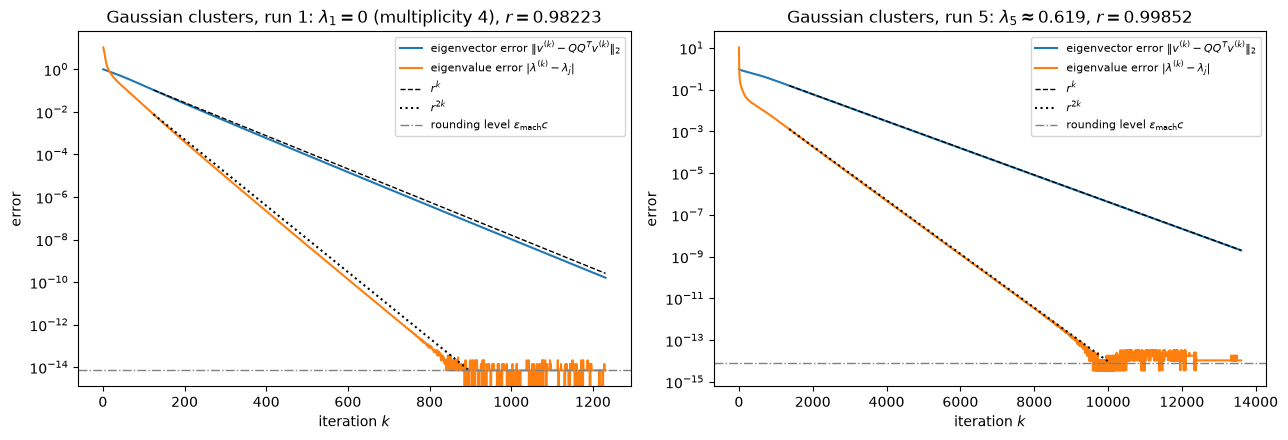

In [41]:
def error_history(L, c, found, Q, lam_ref, maxiter=50000):
    '''
    Run shifted power iteration with deflation and record the eigenvalue and eigenvector errors in every iteration.

    Parameters:
        L: The graph Laplacian, scipy sparse matrix of shape (N,N)
        c: The shift
        found: List of previously computed eigenvectors (deflation)
        Q: Orthonormal basis of the reference eigenspace, np.array of shape (N,m)
        lam_ref: Reference eigenvalue
        maxiter: The maximum number of iterations

    Return:
        lam_err: |lambda^(k) - lambda| per iteration, np.array
        vec_err: Distance from v^(k) to the reference eigenspace, ||v - Q Q^T v||, per iteration, np.array
    '''
    lam_err, vec_err = [], []

    def record(lam, v):
        lam_err.append(abs(lam - lam_ref))
        vec_err.append(la.norm(v - Q @ (Q.T @ v)))

    power_iteration(L, maxiter=maxiter, seed=len(found), c=c, found=found, callback=record)
    return np.array(lam_err), np.array(vec_err)


# Gaussian clusters, reference lambdas, V from spectral_clustering; same seeds as in deflation_convergence
c = 2 * L.diagonal().max()
tol0 = 1e-10 * lambdas[-1]
cases = [(r"run 1: $\lambda_1 = 0$ (multiplicity 4)", 0, [], V[:, :4]),
         (r"run 5: $\lambda_5 \approx 0.619$", 4, list(U_gauss[:, :4].T), V[:, 4:5])]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (title, j, found, Q) in zip(axes, cases):
    lam_err, vec_err = error_history(L, c, found, Q, lambdas[j])
    r = theoretical_rate(lambdas, j, c, tol0)
    ks = np.arange(1, len(vec_err) + 1)
    k0 = len(ks) // 10                          # anchor of the theory lines, after the initial transient

    # Observed rates from log-linear fits; for the eigenvalue only above the rounding floor ~ eps * c
    r_vec = np.exp(np.polyfit(ks[k0:], np.log(vec_err[k0:]), 1)[0])
    above = (ks >= k0) & (lam_err > 1e3 * np.finfo(float).eps * c)   # fit only well above the rounding level
    r_lam = np.exp(np.polyfit(ks[above], np.log(lam_err[above]), 1)[0])
    print(f"{title}: r = {r:.6f}, observed eigenvector rate = {r_vec:.6f}, "
          f"r^2 = {r**2:.6f}, observed eigenvalue rate = {r_lam:.6f}")

    ax.semilogy(ks, vec_err, lw=1.5, label=r"eigenvector error $\|v^{(k)} - QQ^Tv^{(k)}\|_2$")
    ax.semilogy(ks, lam_err, lw=1.5, label=r"eigenvalue error $|\lambda^{(k)} - \lambda_j|$")
    ax.semilogy(ks[k0:], vec_err[k0 - 1] * r**(ks[k0:] - k0), "k--", lw=1, label="$r^k$")
    theory2 = lam_err[k0 - 1] * r**(2 * (ks[k0:] - k0))
    floor = np.finfo(float).eps * c             # rounding level of lambda^(k) = c - (Rayleigh quotient of c*I - L)
    ax.semilogy(ks[k0:][theory2 > floor], theory2[theory2 > floor], "k:", lw=1.5, label="$r^{2k}$")
    ax.axhline(floor, color="grey", lw=1, ls="-.", label=r"rounding level $\varepsilon_{\mathrm{mach}} c$")
    ax.set_xlabel("iteration $k$")
    ax.set_ylabel("error")
    ax.set_title(f"Gaussian clusters, {title}, $r = {r:.5f}$")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Both runs confirm the theory: the eigenvector error follows $r^k$ and the eigenvalue error follows $r^{2k}$, until it reaches the rounding level $\varepsilon_{\mathrm{mach}}c \approx 8\cdot 10^{-15}$. The eigenvalue is therefore accurate to machine precision after about half the iterations, while the stopping criterion (residual $<$ tol) is governed by the slower eigenvector convergence.

In [42]:
# Check the deflated eigenpairs against the reference solution (scipy.linalg.eigh)

U, lams = U_gauss, lams_gauss
n_pairs = U.shape[1]

# 1. Eigenvalue errors
print("Eigenvalue errors |lam_j - lambda_j|:", np.abs(lams - lambdas[:n_pairs]))

# 2. Orthonormality of the computed eigenvectors
print(f"||U^T U - I|| = {la.norm(U.T @ U - np.eye(n_pairs)):.2e}")

# 3. True residuals ||L u_j - lam_j u_j||, without deflation
print("True residuals:", la.norm(L @ U - U * lams, axis=0))

# 4. Eigenspace of lambda = 0: distance from the reference basis V[:, :m] to span(U[:, :m])
Um = U[:, :m]
print(f"Distance between eigenspaces: {la.norm(V[:, :m] - Um @ (Um.T @ V[:, :m])):.2e}")

# 5. Distinct eigenvalues (lambda_5, lambda_6): overlap with the reference eigenvectors, should be ~1
for j in range(m, n_pairs):
    print(f"|u_{j+1}^T v_{j+1}| = {abs(U[:, j] @ V[:, j]):.10f}")

# 6. Clustering with the computed eigenvectors, compared with the Part 1 clustering C
C_pi = KMeans(n_clusters=4, n_init=10, random_state=0).fit(U[:, :4]).labels_
print(f"Adjusted Rand index vs. Part 1: {adjusted_rand_score(C_gauss, C_pi):.4f}")

Eigenvalue errors |lam_j - lambda_j|: [7.10542736e-15 1.77635684e-14 1.06581410e-14 7.10542736e-15
 1.06581410e-14 3.55271368e-15]
||U^T U - I|| = 9.38e-16
True residuals: [9.96196137e-11 9.93019509e-11 9.96088889e-11 9.84530224e-11
 2.20605759e-10 1.43611207e-10]
Distance between eigenspaces: 3.20e-10
|u_5^T v_5| = 1.0000000000
|u_6^T v_6| = 1.0000000000
Adjusted Rand index vs. Part 1: 1.0000


All checks agree with theory. The eigenvalues are correct to rounding level ($\sim \varepsilon_{\text{mach}} c$), the computed vectors are orthonormal to machine precision, and the computed eigenspace of $\lambda = 0$ is within $3.2 \cdot 10^{-10} \approx \sqrt{4}\cdot \text{tol}/(\lambda_5 - \lambda_1)$ of the reference. The true residuals of $u_5, u_6$ are slightly above tol, since deflation inherits the errors of the earlier vectors. K-means on the computed eigenvectors gives exactly the same clustering as in Part 1 (ARI = 1).

In [43]:
# Clustering of the moons with the computed eigenvectors, compared with the Part 1 clustering C_moons
C_pi_moons = KMeans(n_clusters=4, n_init=10, random_state=0).fit(U_moons).labels_
print(f"Adjusted Rand index vs. Part 1 (moons): {adjusted_rand_score(C_moons, C_pi_moons):.4f}")

Adjusted Rand index vs. Part 1 (moons): 1.0000


## QR Iteration

## Lanczos Iteration

### QR iteration



In [51]:
def qr_iteration(L, tol=1e-6, maxiter=1000, shifted=False):
    """
    QR iteration algorithm to approximate the eigenvalues and eigenvectors of the graph Laplacian L

    Parameters:
        L: The input matrix (numpy array or scipy sparse matrix)
        tol: The tolerance for convergence
        maxiter: The maximum number of iterations
        shifted: A boolean that determines if shifted or unshifted QR iteration should run. shifted=True for shifted QR iteration

    Returns:
        A: The matrix obtained after the final QR iteration. Its diagonal entries approximate the eigenvalues of L
        V: A matrix whose columns approximate the corresponding eigenvectors of L
        k: The number of iterations performed
        converged: A boolean indicating whether the algorithm converged within the specified tolerance
        history: A list containing the maximum absolute off-diagonal element after each iteration 
    """
    # Handling the case where L is sparse
    A = L.toarray() if sp.issparse(L) else L.copy()

    V = np.identity(A.shape[0]) # To recover the eigenvectors of A in the end
    I = np.identity(A.shape[0]) # The identity matrix
    converged = False   # Flag to check for convergence
    history = []

    for k in range(1, maxiter+1):

        # If shifted QR iteration
        if shifted:
            mu_k = A[-1,-1]   # mu_k is the last diagonal element of A^(k)
            A = A - mu_k * I    # Shifting: A = A - mu*I

            Q, R = la.qr(A) # Computing the QR-factorization of A
            A = R @ Q + mu_k * I

        # If unshifted QR iteration
        else:
            Q, R = la.qr(A)
            A = R @ Q

        V @= Q  # Computing the matrix consisting of the eigenvectors of A

        error = np.max(np.abs(A - np.diag(np.diag(A)))) # Find the maximum of the off-diagonal elements
        history.append(error)   # Store errors for analysis of convergence

        if error < tol: # Check for convergence
            converged = True
            break

    return A, V, k, converged, history

#### Testing

,dataset,n,tol,maxiter,converged,iterations,time (s),max eigenvalue error,max eigenpair residual,orthogonality error,similarity error,final off-diagonal
0,blobs,400,1e-08,50,False,50,3.948,2.44e-01,8.69e-01,8.27e-14,1.03e-12,4.85e-01
1,blobs,400,1e-08,200,False,200,18.730,1.01e-01,1.56e-01,1.74e-13,2.03e-12,1.43e-01
2,blobs,400,1e-08,500,False,500,39.812,3.55e-02,8.77e-02,3.99e-13,4.89e-12,8.60e-02
3,moons,600,1e-08,50,False,50,8.868,1.73e+00,3.66e+00,9.04e-14,1.01e-12,2.42e+00
4,moons,600,1e-08,200,False,200,40.016,7.99e-01,1.78e+00,1.82e-13,1.93e-12,1.16e+00
5,moons,600,1e-08,500,False,500,91.682,2.86e-01,5.12e-01,3.60e-13,3.52e-12,3.92e-01


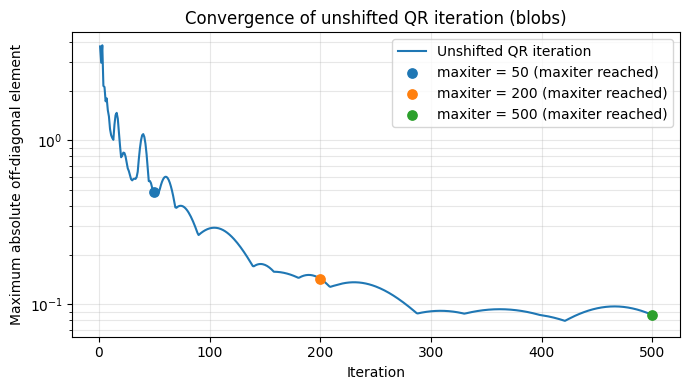

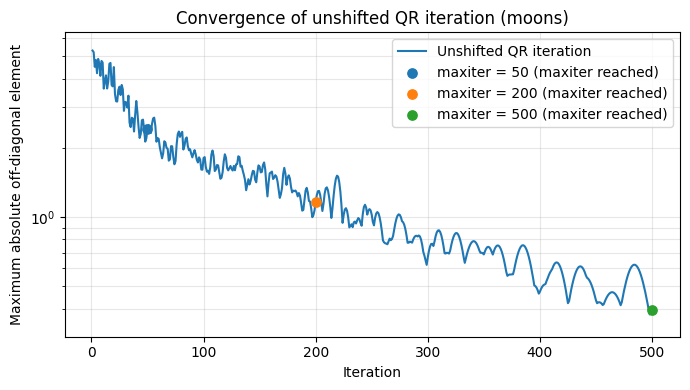

In [50]:
import time
import pandas as pd

tol = 1e-8
maxiters = [50, 200, 500]

results = []
histories = {}

for name, L_test in [("blobs", L_blobs), ("moons", L_moons)]:

    L_dense = L_test.toarray() if sp.issparse(L_test) else L_test

    # Reference solution from SciPy
    lambdas_ref, V_ref = la.eigh(L_dense)

    histories[name] = {}

    for maxiter in maxiters:

        # Run QR iteration and measure computational time
        start = time.perf_counter()
        A_k, V_qr, k, converged, history = qr_iteration(
            L_test, tol=tol, maxiter=maxiter
        )
        elapsed = time.perf_counter() - start

        # Store convergence history
        histories[name][maxiter] = history

        # Extract and sort eigenvalues and eigenvectors
        lambdas_qr = np.diag(A_k)
        idx = np.argsort(lambdas_qr)

        lambdas_qr = lambdas_qr[idx]
        V_qr = V_qr[:, idx]

        # Eigenvalue errors
        eigenvalue_errors = np.abs(lambdas_qr - lambdas_ref)

        # Eigenpair residuals
        residual_matrix = L_dense @ V_qr - V_qr * lambdas_qr
        residuals = la.norm(residual_matrix, axis=0)

        # Orthogonality error
        orthogonality_error = la.norm(
            V_qr.T @ V_qr - np.eye(L_dense.shape[0])
        )

        # Similarity transformation error
        A_sorted = A_k[np.ix_(idx, idx)]
        similarity_error = la.norm(
            V_qr.T @ L_dense @ V_qr - A_sorted
        )

        # Store results
        results.append({
            "dataset": name,
            "n": L_dense.shape[0],
            "tol": tol,
            "maxiter": maxiter,
            "converged": converged,
            "iterations": k,
            "time (s)": elapsed,
            "max eigenvalue error": np.max(eigenvalue_errors),
            "max eigenpair residual": np.max(residuals),
            "orthogonality error": orthogonality_error,
            "similarity error": similarity_error,
            "final off-diagonal": history[-1]
        })

# Create DataFrame
results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "tol": "{:.0e}",
        "time (s)": "{:.3f}",
        "max eigenvalue error": "{:.2e}",
        "max eigenpair residual": "{:.2e}",
        "orthogonality error": "{:.2e}",
        "similarity error": "{:.2e}",
        "final off-diagonal": "{:.2e}"
    })
)

# Plot convergence history for each dataset
for name in ["blobs", "moons"]:

    fig, ax = plt.subplots(figsize=(7, 4))

    # Plot the longest convergence history
    maxiter_longest = max(
        histories[name],
        key=lambda m: len(histories[name][m])
    )
    history = histories[name][maxiter_longest]

    ax.semilogy(
        range(1, len(history) + 1),
        history,
        label="Unshifted QR iteration"
    )

    # Mark the final iteration of each run
    for maxiter in maxiters:
        hist = histories[name][maxiter]

        run = results_df[
            (results_df["dataset"] == name) &
            (results_df["maxiter"] == maxiter)
        ].iloc[0]

        status = "converged" if run["converged"] else "maxiter reached"

        ax.scatter(
            len(hist),
            hist[-1],
            s=45,
            zorder=3,
            label=f"maxiter = {maxiter} ({status})"
        )

        ax.set_ylim(
            min(history) * 0.8,
            max(history) * 1.2
        )

    ax.set_xlabel("Iteration")
    ax.set_ylabel("Maximum absolute off-diagonal element")
    ax.set_title(f"Convergence of unshifted QR iteration ({name})")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

#### Unshifted QR iteration

We first implemented the standard unshifted QR iteration and tested it on the blobs and moons graph Laplacians, using a tolerance of (10^{-8}) and a maximum of 50, 200, and 500 iterations.

Neither dataset reached the convergence tolerance within 500 iterations, although the maximum off-diagonal elements decreased to approximately 0.086 for blobs and 0.392 for moons. The convergence plots show an overall decreasing trend, with slower progress in later iterations.

The orthogonality and similarity errors remained small, indicating numerically consistent transformations. However, the eigenpair residuals were still relatively large, and the full QR factorizations resulted in considerable computational costs. 

These results provide a baseline for investigating further improvements to convergence and runtime, such as using shifting and using Householder transformations to reduce the graph Laplacians to Hessenberg-form.

#### Shifted QR iteration



#### Shifted QR iteration with A Hessenberg

In [ ]:
test_matrix = np.array([
    [2., 1., 0.],
    [1., 2., 1.],
    [0., 1., 2.]
])

start = time.perf_counter()
A_test, V_test, k_test, conv_test, hist_test = qr_iteration(test_matrix, _, _, True)
elapsed = time.perf_counter() - start

# Store convergence history
histories[name][maxiter] = history

# Extract and sort eigenvalues and eigenvectors
lambdas_qr = np.diag(A_k)
idx = np.argsort(lambdas_qr)

lambdas_qr = lambdas_qr[idx]
V_qr = V_qr[:, idx]

# Eigenvalue errors
eigenvalue_errors = np.abs(lambdas_qr - lambdas_ref)

# Eigenpair residuals
residual_matrix = L_dense @ V_qr - V_qr * lambdas_qr
residuals = la.norm(residual_matrix, axis=0)

# Orthogonality error
orthogonality_error = la.norm(V_qr.T @ V_qr - np.eye(L_dense.shape[0]))

# Similarity transformation error
A_sorted = A_k[np.ix_(idx, idx)]
similarity_error = la.norm(V_qr.T @ L_dense @ V_qr - A_sorted)

print()